# Experiment 6 — GloVe Word Embeddings & N-gram Language Model

**Part 1:** Implement GloVe to generate word embeddings and find words most similar to **"king"**
- 1A. From scratch (NumPy, no pretrained model)
- 1B. Using a pretrained model (Gensim)

**Part 2:** Statistical N-gram language model from scratch to predict the next word

## Part 1A — GloVe from scratch
### Step 1: Load and preprocess the corpus

In [1]:
import re, os
import numpy as np
from collections import Counter, defaultdict

np.random.seed(42)

# Upload glove_corpus.txt to the working directory (in Colab: Files panel → Upload)
if os.path.exists("glove_corpus.txt"):
    with open("glove_corpus.txt", encoding="utf-8") as f:
        sentences = [l.strip() for l in f if l.strip()]
else:
    raise FileNotFoundError("Place glove_corpus.txt in the working directory")

def tokenize(s):
    return re.findall(r"[a-z]+", s.lower())

# Remove very common function words so the small corpus focuses on content words
stopwords = {"the", "a", "is", "and", "of", "in", "at", "to"}
tokenized = [[w for w in tokenize(s) if w not in stopwords] for s in sentences]

print("Sentences:", len(sentences))
for t in tokenized[:5]: print(t)

Sentences: 24
['king', 'rules', 'kingdom']
['queen', 'rules', 'kingdom']
['king', 'powerful', 'man']
['queen', 'wise', 'woman']
['man', 'strong', 'brave']


### Step 2: Build vocabulary

In [2]:
word_counts = Counter(w for s in tokenized for w in s)
vocab = sorted(word_counts)
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}
V = len(vocab)
print("Vocabulary size:", V)
print(vocab)

Vocabulary size: 61
['around', 'books', 'brave', 'cat', 'computer', 'conducts', 'data', 'daughter', 'develops', 'doctor', 'dog', 'drinks', 'earth', 'eats', 'food', 'gives', 'heat', 'house', 'information', 'intelligent', 'kind', 'king', 'kingdom', 'laboratory', 'learn', 'light', 'live', 'lives', 'man', 'milk', 'moon', 'new', 'night', 'palace', 'patient', 'powerful', 'prince', 'princess', 'processes', 'queen', 'read', 'research', 'revolves', 'royal', 'rule', 'rules', 'school', 'scientist', 'shines', 'software', 'son', 'strong', 'students', 'sun', 'teacher', 'teaches', 'things', 'together', 'treats', 'wise', 'woman']


### Step 3: Build the co-occurrence matrix $X$
For every word, count context words within a window; each pair is weighted by $1/d$ where $d$ is the distance (as in the original GloVe paper).

In [3]:
WINDOW = 3
X = np.zeros((V, V), dtype=np.float64)

for sent in tokenized:
    ids = [word2idx[w] for w in sent]
    for i, wi in enumerate(ids):
        for j in range(max(0, i - WINDOW), min(len(ids), i + WINDOW + 1)):
            if i != j:
                X[wi, ids[j]] += 1.0 / abs(i - j)

print("Non-zero co-occurrence pairs:", int((X > 0).sum()))
k = word2idx["king"]
print("Co-occurrences of 'king':",
      {idx2word[j]: round(X[k, j], 2) for j in np.nonzero(X[k])[0]})

Non-zero co-occurrence pairs: 220
Co-occurrences of 'king': {'kingdom': np.float64(0.5), 'lives': np.float64(1.0), 'man': np.float64(0.5), 'palace': np.float64(0.33), 'powerful': np.float64(1.0), 'prince': np.float64(0.5), 'queen': np.float64(1.0), 'royal': np.float64(0.5), 'rule': np.float64(0.5), 'rules': np.float64(1.0), 'son': np.float64(1.0), 'together': np.float64(0.33)}


### Step 4: Train GloVe
Objective (weighted least squares):

$$J = \sum_{i,j:\,X_{ij}>0} f(X_{ij})\left(w_i^T \tilde w_j + b_i + \tilde b_j - \log X_{ij}\right)^2$$

with weighting function $f(x) = (x/x_{max})^{\alpha}$ if $x < x_{max}$, else 1. Optimised with AdaGrad.

In [4]:
EMB_DIM, X_MAX, ALPHA, LR, EPOCHS = 20, 10, 0.75, 0.05, 1000

W  = (np.random.rand(V, EMB_DIM) - 0.5) / EMB_DIM   # main word vectors
Wc = (np.random.rand(V, EMB_DIM) - 0.5) / EMB_DIM   # context word vectors
b  = np.zeros(V); bc = np.zeros(V)

# AdaGrad accumulators
gW, gWc = np.ones_like(W), np.ones_like(Wc)
gb, gbc = np.ones_like(b), np.ones_like(bc)

rows, cols = np.nonzero(X)
pairs = list(zip(rows, cols))
weighting = lambda x: (x / X_MAX) ** ALPHA if x < X_MAX else 1.0

losses = []
for epoch in range(EPOCHS):
    np.random.shuffle(pairs)
    total = 0.0
    for i, j in pairs:
        x = X[i, j]
        diff = W[i] @ Wc[j] + b[i] + bc[j] - np.log(x)
        fx = weighting(x)
        total += 0.5 * fx * diff ** 2

        g = fx * diff
        grad_wi, grad_wj = g * Wc[j], g * W[i]

        W[i]  -= LR * grad_wi / np.sqrt(gW[i]);  gW[i]  += grad_wi ** 2
        Wc[j] -= LR * grad_wj / np.sqrt(gWc[j]); gWc[j] += grad_wj ** 2
        b[i]  -= LR * g / np.sqrt(gb[i]);        gb[i]  += g ** 2
        bc[j] -= LR * g / np.sqrt(gbc[j]);       gbc[j] += g ** 2
    losses.append(total)
    if epoch % 100 == 0 or epoch == EPOCHS - 1:
        print(f"Epoch {epoch:4d}  loss = {total:.4f}")

# Final embedding = sum of word and context vectors (as recommended in the paper)
embeddings = W + Wc

Epoch    0  loss = 3.5358
Epoch  100  loss = 1.5526
Epoch  200  loss = 1.3066
Epoch  300  loss = 0.8967
Epoch  400  loss = 0.5038
Epoch  500  loss = 0.1826
Epoch  600  loss = 0.0556
Epoch  700  loss = 0.0219
Epoch  800  loss = 0.0112
Epoch  900  loss = 0.0066
Epoch  999  loss = 0.0043


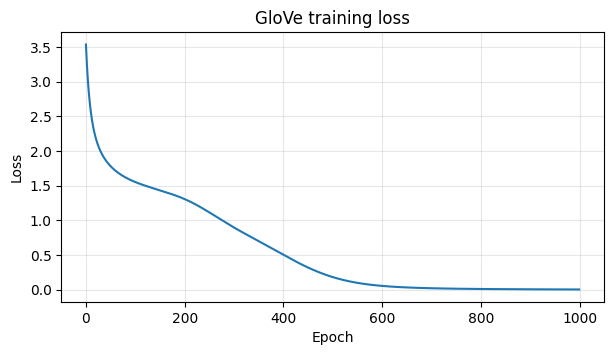

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 3.5))
plt.plot(losses)
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("GloVe training loss")
plt.grid(alpha=0.3); plt.show()

### Step 5: Find words most similar to "king" (cosine similarity)

In [6]:
def cosine(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-10)

def most_similar(word, topn=5):
    v = embeddings[word2idx[word]]
    sims = [(w, cosine(v, embeddings[i])) for w, i in word2idx.items() if w != word]
    return sorted(sims, key=lambda t: -t[1])[:topn]

print("Most similar to 'king' (scratch GloVe):")
for w, s in most_similar("king", 5):
    print(f"  {w:12s} {s:.4f}")

Most similar to 'king' (scratch GloVe):
  son          0.9813
  queen        0.9660
  wise         0.9437
  powerful     0.9150
  prince       0.8279


### Step 6: Visualise the embeddings (PCA to 2-D)

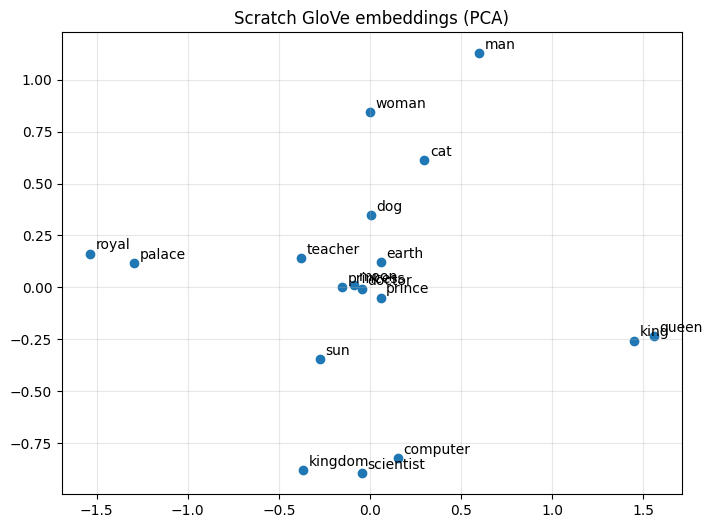

In [7]:
from sklearn.decomposition import PCA
show = ["king","queen","man","woman","prince","princess","kingdom","palace","royal",
        "cat","dog","sun","moon","earth","computer","scientist","teacher","doctor"]
show = [w for w in show if w in word2idx]
pts = PCA(n_components=2).fit_transform(embeddings[[word2idx[w] for w in show]])

plt.figure(figsize=(8, 6))
plt.scatter(pts[:, 0], pts[:, 1])
for w, (x, y) in zip(show, pts):
    plt.annotate(w, (x, y), xytext=(4, 3), textcoords="offset points")
plt.title("Scratch GloVe embeddings (PCA)"); plt.grid(alpha=0.3); plt.show()

> **Note:** the corpus has only 24 sentences, so scratch embeddings capture local co-occurrence (king ↔ queen, prince, son, powerful) rather than deep semantics. Results can vary slightly with the random seed.

## Part 1B — GloVe using a pretrained model (Gensim)
Uses `glove-wiki-gigaword-100` (trained on Wikipedia + Gigaword, 6B tokens). Needs internet on first run (~128 MB).

In [8]:
!pip install -q gensim

In [9]:
import gensim.downloader as api
glove = api.load("glove-wiki-gigaword-100")
print("Vocabulary size:", len(glove.key_to_index), "| Dimensions:", glove.vector_size)

URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get issuer certificate (_ssl.c:1006)>

In [ ]:
print("Most similar to 'king' (pretrained GloVe):")
for w, s in glove.most_similar("king", topn=10):
    print(f"  {w:12s} {s:.4f}")

In [ ]:
# Classic analogy: king - man + woman ≈ ?
print("king - man + woman =", glove.most_similar(positive=["king", "woman"], negative=["man"], topn=5))
print("sim(king, queen) =", round(glove.similarity("king", "queen"), 4))
print("sim(king, cat)   =", round(glove.similarity("king", "cat"), 4))

In [ ]:
# Similarity for words from our own corpus using pretrained vectors
for w in ["king", "queen", "computer", "cat", "sun"]:
    print(f"{w:10s} ->", [x for x, _ in glove.most_similar(w, topn=5)])

## Part 2 — N-gram Language Model from scratch
### Step 1: Corpus and preprocessing
Each sentence is padded with `<s>` start tokens and an `</s>` end token.

In [15]:
ngram_corpus = """natural language processing is a branch of artificial intelligence.
natural language processing enables computers to understand human language.
machine learning is a branch of artificial intelligence.
deep learning is a part of machine learning.
language models learn patterns from text data.
a language model predicts the next word in a sentence.
natural language processing uses language models.
artificial intelligence includes machine learning and deep learning."""

ng_sentences = [re.findall(r"[a-z]+", s.lower()) for s in ngram_corpus.strip().split("\n")]
ng_vocab = sorted({w for s in ng_sentences for w in s} | {"</s>"})
print("Sentences:", len(ng_sentences), "| Vocabulary size:", len(ng_vocab))

Sentences: 8 | Vocabulary size: 35


### Step 2: N-gram model class
$$P(w_n \mid w_{n-N+1}^{n-1}) = \frac{C(w_{n-N+1}^{n}) + k}{C(w_{n-N+1}^{n-1}) + k|V|}$$
(add-k / Laplace smoothing; $k=0$ gives the plain MLE estimate).

In [16]:
class NGramModel:
    def __init__(self, n, k=1.0):
        self.n, self.k = n, k
        self.ngram_counts = defaultdict(Counter)   # context tuple -> Counter(next word)
        self.context_counts = Counter()

    def _pad(self, sent):
        return ["<s>"] * (self.n - 1) + sent + ["</s>"]

    def fit(self, sentences):
        self.vocab = sorted({w for s in sentences for w in s} | {"</s>"})
        for s in sentences:
            toks = self._pad(s)
            for i in range(self.n - 1, len(toks)):
                ctx = tuple(toks[i - self.n + 1:i])
                self.ngram_counts[ctx][toks[i]] += 1
                self.context_counts[ctx] += 1
        return self

    def prob(self, context, word):
        ctx = tuple(context[-(self.n - 1):]) if self.n > 1 else ()
        V = len(self.vocab)
        return (self.ngram_counts[ctx][word] + self.k) / (self.context_counts[ctx] + self.k * V)

    def predict_next(self, text, topn=3):
        ctx = ["<s>"] * (self.n - 1) + re.findall(r"[a-z]+", text.lower())
        scores = [(w, self.prob(ctx, w)) for w in self.vocab]
        return sorted(scores, key=lambda t: -t[1])[:topn]

    def generate(self, seed, max_len=12):
        words = re.findall(r"[a-z]+", seed.lower())
        for _ in range(max_len):
            nxt = self.predict_next(" ".join(words), 1)[0][0]
            if nxt == "</s>": break
            words.append(nxt)
        return " ".join(words)

    def perplexity(self, sentences):
        log_p, N = 0.0, 0
        for s in sentences:
            toks = self._pad(s)
            for i in range(self.n - 1, len(toks)):
                log_p += np.log(self.prob(toks[:i], toks[i])); N += 1
        return np.exp(-log_p / N)

### Step 3: Train unigram, bigram and trigram models

In [17]:
models = {n: NGramModel(n, k=0.01).fit(ng_sentences) for n in (1, 2, 3)}

print("Sample bigram counts:")
for ctx in [("natural",), ("language",), ("machine",), ("is",)]:
    print(f"  {ctx[0]:10s} ->", dict(models[2].ngram_counts[ctx]))

Sample bigram counts:
  natural    -> {'language': 3}
  language   -> {'processing': 3, '</s>': 1, 'models': 2, 'model': 1}
  machine    -> {'learning': 3}
  is         -> {'a': 3}


### Step 4: Next-word prediction

In [18]:
tests = ["natural language", "machine", "artificial", "deep learning is a",
         "language models learn", "a language model predicts the"]
for text in tests:
    print(f"\nInput: '{text}'")
    for n in (2, 3):
        preds = ", ".join(f"{w} ({p:.3f})" for w, p in models[n].predict_next(text))
        print(f"  {n}-gram → {preds}")


Input: 'natural language'
  2-gram → processing (0.410), models (0.273), </s> (0.137)
  3-gram → processing (0.899), </s> (0.003), a (0.003)

Input: 'machine'
  2-gram → learning (0.899), </s> (0.003), a (0.003)
  3-gram → learning (0.748), </s> (0.007), a (0.007)

Input: 'artificial'
  2-gram → intelligence (0.899), </s> (0.003), a (0.003)
  3-gram → intelligence (0.748), </s> (0.007), a (0.007)

Input: 'deep learning is a'
  2-gram → branch (0.376), language (0.189), part (0.189)
  3-gram → branch (0.600), part (0.301), </s> (0.003)

Input: 'language models learn'
  2-gram → patterns (0.748), </s> (0.007), a (0.007)
  3-gram → patterns (0.748), </s> (0.007), a (0.007)

Input: 'a language model predicts the'
  2-gram → next (0.748), </s> (0.007), a (0.007)
  3-gram → next (0.748), </s> (0.007), a (0.007)


### Step 5: Sentence generation (greedy)

In [19]:
for seed in ["natural", "machine learning", "deep", "a language"]:
    print(f"{seed:18s} → {models[3].generate(seed)}")

natural            → natural language processing enables computers to understand human language
machine learning   → machine learning
deep               → deep learning
a language         → a language model predicts the next word in a sentence


### Step 6: Evaluate with perplexity (lower is better)

In [20]:
test_sents = [re.findall(r"[a-z]+", s) for s in
              ["machine learning is a branch of artificial intelligence",
               "deep learning is a part of artificial intelligence"]]
for n, m in models.items():
    print(f"{n}-gram  train PPL = {m.perplexity(ng_sentences):7.3f}   "
          f"test PPL = {m.perplexity(test_sents):7.3f}")

1-gram  train PPL =  26.642   test PPL =  21.690
2-gram  train PPL =   2.071   test PPL =   1.949
3-gram  train PPL =   1.746   test PPL =   2.394


## Conclusion
- **GloVe from scratch** builds a distance-weighted co-occurrence matrix and learns vectors by weighted least squares on $\log X_{ij}$; on the small corpus, "king" lands near *son, queen, powerful, prince*.
- **Pretrained GloVe (Gensim)** returns semantically rich neighbours (*prince, queen, monarch, throne*) and solves *king − man + woman ≈ queen*, showing the value of large-scale training data.
- **N-gram model** predicts the next word from counts of preceding words; higher-order models (trigram) give sharper, more context-aware predictions and lower training perplexity, while smoothing handles unseen sequences.